CONFIGURACIÓN Y CARGA

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from etl.cleaning import FEATURES          # misma lista de variables que el resto del proyecto

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "happiness_unified.csv"
FIG_DIR = PROJECT_ROOT / "docs" / "evidence" / "features"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "happiness_score"

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(781, 9)


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
0,Afghanistan,2015,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719,3.575
1,Albania,2015,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413,4.959
2,Algeria,2015,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383,5.605
3,Angola,2015,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122,4.033
4,Argentina,2015,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484,6.574


ESTADISTICAS DESCRIPTIVAS

In [2]:
df[FEATURES + [TARGET]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
gdp,781.0,0.915,0.405,0.000,0.605,0.982,1.234,1.871
family,781.0,1.079,0.330,0.000,0.870,1.125,1.328,1.644
health,781.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141
freedom,781.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724
generosity,781.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838
corruption,781.0,0.125,0.106,0.000,0.054,0.091,0.156,0.552
happiness_score,781.0,5.377,1.127,2.693,4.509,5.321,6.182,7.769


DISTRIBUCIONES

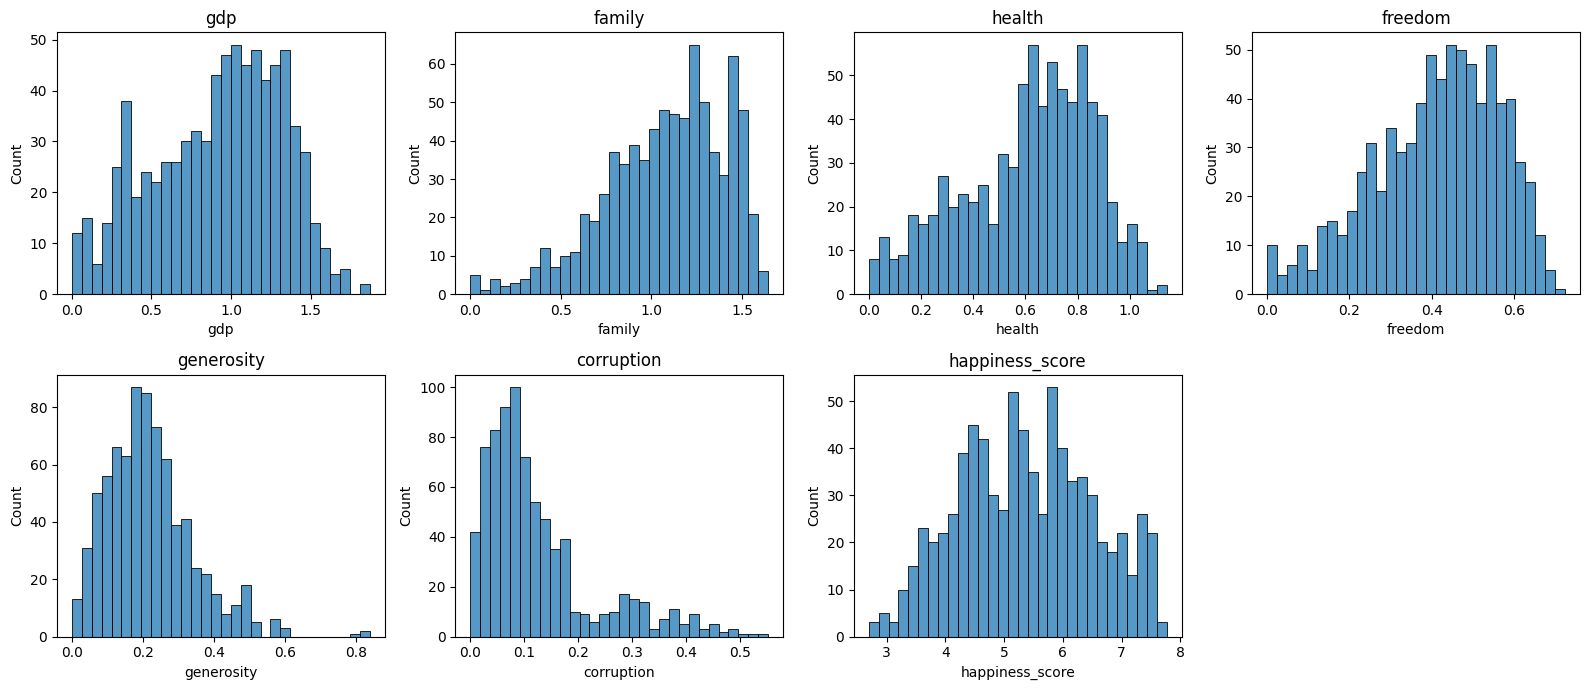

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, FEATURES + [TARGET]):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")                  # son 7 gráficos en 8 espacios
plt.tight_layout()
fig.savefig(FIG_DIR / "distributions.png", dpi=150)
plt.show()

CORRELACIONES

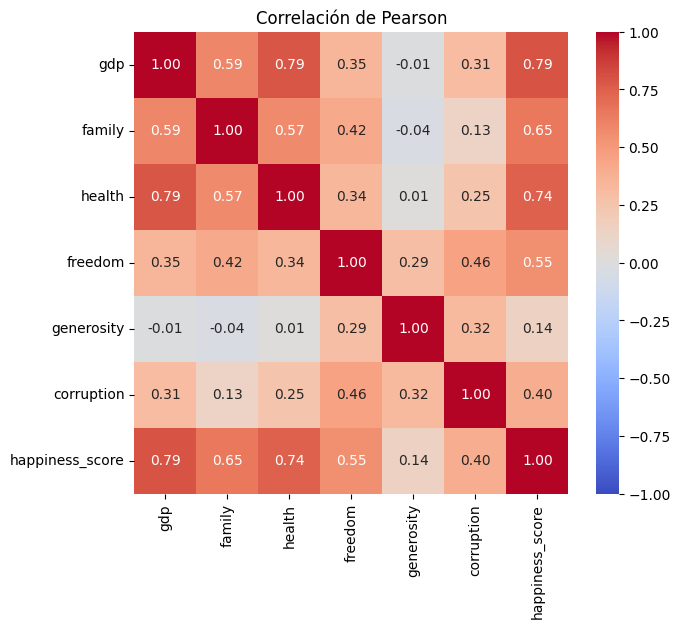

gdp           0.790
health        0.743
family        0.651
freedom       0.553
corruption    0.398
generosity    0.138
Name: happiness_score, dtype: float64

In [4]:
corr = df[FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Pearson")
fig.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3)

CADA VARIABLE FRENTE AL PUNTAJE

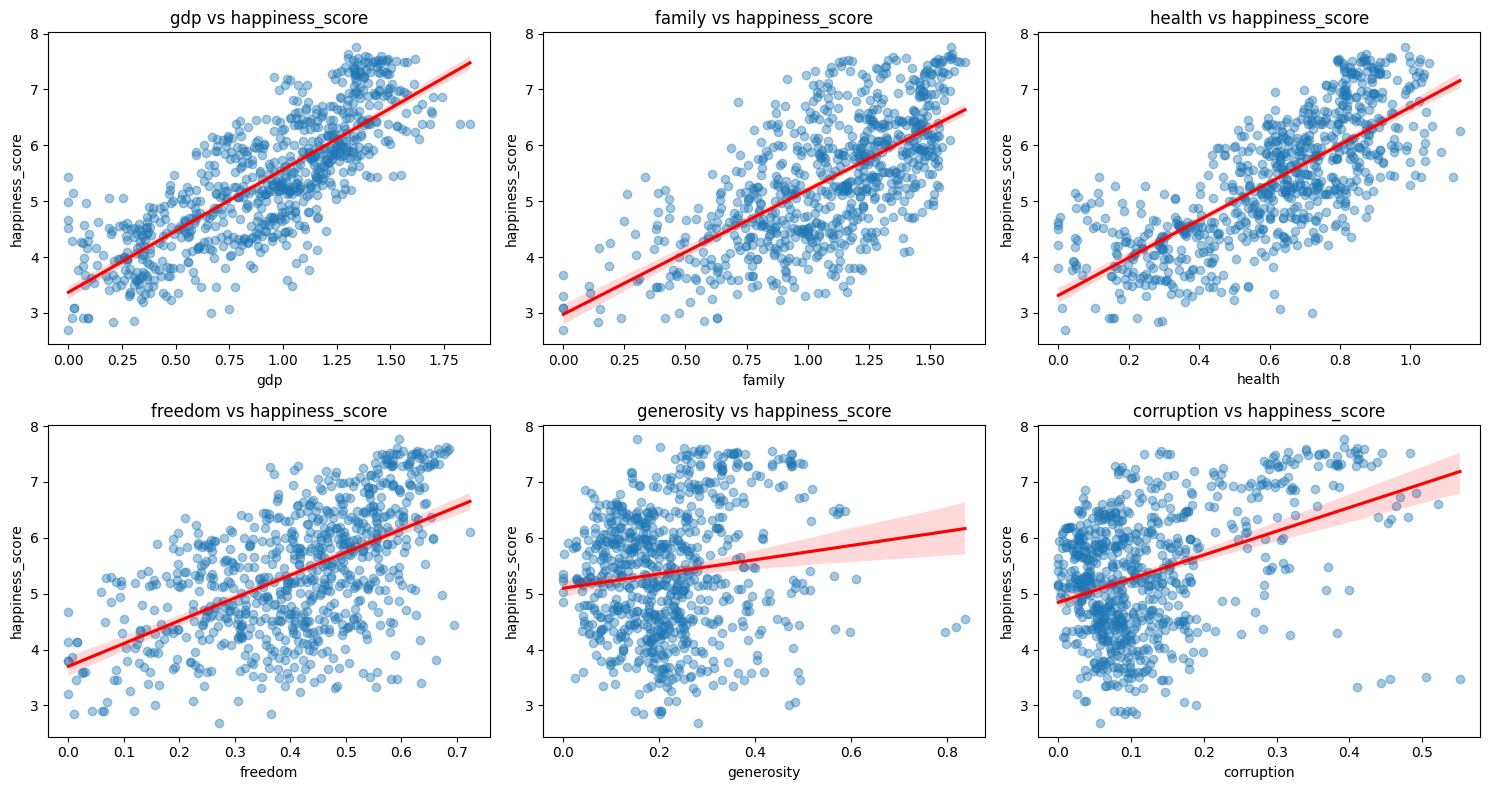

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, FEATURES):
    sns.regplot(data=df, x=col, y=TARGET, ax=ax,
                scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs {TARGET}")
plt.tight_layout()
fig.savefig(FIG_DIR / "features_vs_target.png", dpi=150)
plt.show()

DIVISIÓN

In [6]:
import numpy as np
import joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X, y = df[FEATURES], df[TARGET]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df["country"]))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

shared = set(df["country"].iloc[train_idx]) & set(df["country"].iloc[test_idx])
print(f"Entrenamiento: {len(X_train)} filas | Prueba: {len(X_test)} filas")
print(f"Países en ambos grupos: {len(shared)}")   # debe ser 0

Entrenamiento: 541 filas | Prueba: 240 filas
Países en ambos grupos: 0


PIPELINE Y FUNCIÓN DE EVALUACIÓN

In [7]:
def build_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])

def evaluate(cols):
    pipe = build_pipeline().fit(X_train[cols], y_train)
    pred = pipe.predict(X_test[cols])
    return {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    }

COMPARACIÓN DE CONJUNTOS DE VARIABLES

In [8]:
experiments = {
    "Solo gdp + health": ["gdp", "health"],
    "Seis sin generosity": [c for c in FEATURES if c != "generosity"],
    "Seis variables": FEATURES,
}
results = pd.DataFrame({name: evaluate(cols) for name, cols in experiments.items()}).T.round(3)
results.to_csv(FIG_DIR / "feature_set_comparison.csv")
results

,MAE,RMSE,R2
Solo gdp + health,0.523,0.635,0.724
Seis sin generosity,0.434,0.569,0.778
Seis variables,0.432,0.562,0.784


MODELO FINAL, MÉTRICAS Y COEFICIENTES

In [9]:
final = build_pipeline().fit(X_train, y_train)
pred = final.predict(X_test)

metrics = {
    "MAE": round(mean_absolute_error(y_test, pred), 3),
    "RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred))), 3),
    "R2": round(r2_score(y_test, pred), 3),
}
print(metrics)

coef = pd.Series(final.named_steps["model"].coef_, index=FEATURES).round(3)
print("\nCoeficientes (variables escaladas):")
print(coef.sort_values(ascending=False))

{'MAE': 0.432, 'RMSE': 0.562, 'R2': 0.784}

Coeficientes (variables escaladas):
gdp           0.445
freedom       0.242
family        0.240
health        0.208
corruption    0.073
generosity    0.063
dtype: float64


GUARDAR Y VERIFICAR MODEL.PK

In [10]:
import json

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final, MODELS_DIR / "model.pkl")
(MODELS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

# Verificación: cargarlo y predecir con una fila nueva, igual que hará el consumer
loaded = joblib.load(MODELS_DIR / "model.pkl")
sample = X_test.iloc[[0]]
print("Variables que espera el modelo:", list(loaded.feature_names_in_))
print("Predicción:", round(float(loaded.predict(sample)[0]), 3), "| Real:", round(float(y_test.iloc[0]), 3))

Variables que espera el modelo: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
Predicción: 5.163 | Real: 5.605


In [11]:
STREAM_DIR = PROJECT_ROOT / "data" / "streaming"
STREAM_DIR.mkdir(parents=True, exist_ok=True)

stream = (
    df.iloc[test_idx][["country", "year"] + FEATURES + [TARGET]]
    .sort_values(["year", "country"])
    .reset_index(drop=True)
)
stream.to_csv(STREAM_DIR / "happiness_stream.csv", index=False, encoding="utf-8")
print("Filas:", len(stream), "| Países distintos:", stream["country"].nunique())

Filas: 240 | Países distintos: 50
